In [ ]:
import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU memory (GB):",
          round(torch.cuda.get_device_properties(0).total_memory / 1e9, 2))

In [ ]:
!pip -q install datasets transformers sentencepiece sacrebleu accelerate evaluate

In [ ]:
from datasets import load_dataset

# Load English-French parallel text
dataset = load_dataset(
    "Helsinki-NLP/opus_books",
    "en-fr",
    split="train"
)

print("Dataset loaded successfully!")
print("Total translation pairs:", len(dataset))

print("\nFirst example:")
print(dataset[0])

In [ ]:
import pandas as pd

# Extract English-French translation pairs
pairs = [
    (
        row["translation"]["en"],
        row["translation"]["fr"]
    )
    for row in dataset
]

# Create DataFrame
df = pd.DataFrame(
    pairs,
    columns=["English", "French"]
)

print("Total sentence pairs:", len(df))

print("\nFirst five examples:")
display(df.head())

In [ ]:
# Remove duplicate translation pairs
df = df.drop_duplicates().reset_index(drop=True)

# Calculate sentence lengths
df["English_Length"] = df["English"].str.split().str.len()
df["French_Length"] = df["French"].str.split().str.len()

print("Unique sentence pairs:", len(df))

print("\nSentence length statistics:")
display(
    df[["English_Length", "French_Length"]].describe()
)

In [ ]:
print("Dataset available:", "df" in globals())

if "df" in globals():
    print("Dataset rows:", len(df))

# 2. Dataset Preprocessing and Splitting

The English-French parallel corpus is filtered to retain
sentence pairs containing 3 to 30 words.

A reproducible subset of 10,000 sentence pairs is selected
for training and evaluating the translation models.

In [ ]:
# Keep sentence pairs containing 3 to 30 words
filtered_df = df[
    (df["English_Length"] >= 3) &
    (df["English_Length"] <= 30) &
    (df["French_Length"] >= 3) &
    (df["French_Length"] <= 30)
].copy()

# Remove missing values
filtered_df = filtered_df.dropna(
    subset=["English", "French"]
)

# Remove empty sentences
filtered_df = filtered_df[
    (filtered_df["English"].str.strip() != "") &
    (filtered_df["French"].str.strip() != "")
]

filtered_df = filtered_df.reset_index(drop=True)

print("Original unique pairs:", len(df))
print("Filtered sentence pairs:", len(filtered_df))

print("\nSample filtered pairs:")
display(filtered_df[["English", "French"]].head())

In [ ]:
# Select 10,000 sentence pairs
subset_size = 10000

assert len(filtered_df) >= subset_size, \
    "Not enough sentence pairs after filtering"

selected_df = filtered_df.sample(
    n=subset_size,
    random_state=42
).reset_index(drop=True)

print("Selected sentence pairs:", len(selected_df))

display(selected_df[["English", "French"]].head())

In [ ]:
from sklearn.model_selection import GroupShuffleSplit

# Normalize source text for grouping
selected_df["Source_Group"] = (
    selected_df["English"]
    .str.strip()
    .str.casefold()
)

# First split: 80% training, 20% held out
splitter1 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, temp_idx = next(
    splitter1.split(
        selected_df,
        groups=selected_df["Source_Group"]
    )
)

train_df = selected_df.iloc[train_idx].copy()
temp_df = selected_df.iloc[temp_idx].copy()

# Second split: validation and test
splitter2 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.5,
    random_state=42
)

val_idx, test_idx = next(
    splitter2.split(
        temp_df,
        groups=temp_df["Source_Group"]
    )
)

val_df = temp_df.iloc[val_idx].copy()
test_df = temp_df.iloc[test_idx].copy()

# Reset indices
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("Training pairs:", len(train_df))
print("Validation pairs:", len(val_df))
print("Testing pairs:", len(test_df))

print("Total pairs:",
      len(train_df) + len(val_df) + len(test_df))

In [ ]:
train_sources = set(train_df["Source_Group"])
val_sources = set(val_df["Source_Group"])
test_sources = set(test_df["Source_Group"])

print("Train/Validation overlap:",
      len(train_sources & val_sources))

print("Train/Test overlap:",
      len(train_sources & test_sources))

print("Validation/Test overlap:",
      len(val_sources & test_sources))

assert train_sources.isdisjoint(val_sources)
assert train_sources.isdisjoint(test_sources)
assert val_sources.isdisjoint(test_sources)

print("\nDataset split verification successful!")

In [ ]:
import os

# Create data directory
os.makedirs("data", exist_ok=True)

# Save only the translation columns
train_df[["English", "French"]].to_csv(
    "data/train.csv",
    index=False
)

val_df[["English", "French"]].to_csv(
    "data/validation.csv",
    index=False
)

test_df[["English", "French"]].to_csv(
    "data/test.csv",
    index=False
)

print("Datasets saved successfully!")

print("\nSaved files:")
print(os.listdir("data"))

# 3. Basic Transformer Encoder–Decoder

This section implements a Transformer-based English-to-French
machine translation model from scratch using PyTorch.

The model uses:
- Source and target token embeddings
- Positional encoding
- Multi-head attention
- Transformer encoder and decoder
- Autoregressive translation generation

In [ ]:
from collections import Counter
import re

# Special tokens
PAD = "<pad>"
UNK = "<unk>"
BOS = "<bos>"
EOS = "<eos>"

special_tokens = [PAD, UNK, BOS, EOS]

def tokenize(text):
    return re.findall(r"\w+|[^\w\s]", text.lower(), re.UNICODE)

def build_vocab(sentences, max_size=8000):
    counter = Counter()

    for sentence in sentences:
        counter.update(tokenize(sentence))

    vocab = {
        token: i
        for i, token in enumerate(special_tokens)
    }

    for word, count in counter.most_common():
        if word not in vocab:
            if len(vocab) >= max_size:
                break
            vocab[word] = len(vocab)

    return vocab


src_vocab = build_vocab(train_df["English"])
tgt_vocab = build_vocab(train_df["French"])

print("English vocabulary size:", len(src_vocab))
print("French vocabulary size:", len(tgt_vocab))

In [ ]:
MAX_LEN = 40

def encode_sentence(sentence, vocab):
    tokens = tokenize(sentence)

    ids = [vocab[BOS]]

    ids += [
        vocab.get(token, vocab[UNK])
        for token in tokens[:MAX_LEN - 2]
    ]

    ids.append(vocab[EOS])

    return ids


# Example
example = train_df.iloc[0]

english_ids = encode_sentence(
    example["English"],
    src_vocab
)

french_ids = encode_sentence(
    example["French"],
    tgt_vocab
)

print("English:", example["English"])
print("English token IDs:", english_ids)

print("\nFrench:", example["French"])
print("French token IDs:", french_ids)

In [ ]:
import torch
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence

class TranslationDataset(Dataset):

    def __init__(self, dataframe):
        self.data = dataframe.reset_index(drop=True)

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        row = self.data.iloc[idx]

        src = encode_sentence(
            row["English"],
            src_vocab
        )

        tgt = encode_sentence(
            row["French"],
            tgt_vocab
        )

        return (
            torch.tensor(src, dtype=torch.long),
            torch.tensor(tgt, dtype=torch.long)
        )


def collate_batch(batch):
    src_batch, tgt_batch = zip(*batch)

    src_batch = pad_sequence(
        src_batch,
        batch_first=True,
        padding_value=src_vocab[PAD]
    )

    tgt_batch = pad_sequence(
        tgt_batch,
        batch_first=True,
        padding_value=tgt_vocab[PAD]
    )

    return src_batch, tgt_batch


train_loader = DataLoader(
    TranslationDataset(train_df),
    batch_size=32,
    shuffle=True,
    collate_fn=collate_batch
)

val_loader = DataLoader(
    TranslationDataset(val_df),
    batch_size=32,
    shuffle=False,
    collate_fn=collate_batch
)

test_loader = DataLoader(
    TranslationDataset(test_df),
    batch_size=32,
    shuffle=False,
    collate_fn=collate_batch
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

In [ ]:
src_batch, tgt_batch = next(iter(train_loader))

print("English batch shape:", src_batch.shape)
print("French batch shape:", tgt_batch.shape)

print("\nFirst English sequence:")
print(src_batch[0])

print("\nFirst French sequence:")
print(tgt_batch[0])

# 4. Basic Transformer Architecture

A Transformer encoder-decoder is implemented using PyTorch.
Sinusoidal positional encoding is added to token embeddings
to represent word order.

In [ ]:
import torch
import torch.nn as nn
import math

class PositionalEncoding(nn.Module):

    def __init__(self, d_model, max_len=500):
        super().__init__()

        pe = torch.zeros(max_len, d_model)

        position = torch.arange(
            0, max_len, dtype=torch.float
        ).unsqueeze(1)

        div_term = torch.exp(
            torch.arange(0, d_model, 2).float()
            * (-math.log(10000.0) / d_model)
        )

        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)

        self.register_buffer(
            "pe", pe.unsqueeze(0)
        )

    def forward(self, x):
        return x + self.pe[:, :x.size(1), :]


print("Positional Encoding implemented!")

In [ ]:
class TranslationTransformer(nn.Module):

    def __init__(
        self,
        src_vocab_size,
        tgt_vocab_size,
        d_model=128,
        nhead=4,
        num_layers=2,
        dim_feedforward=512,
        dropout=0.1
    ):
        super().__init__()

        self.d_model = d_model

        self.src_embedding = nn.Embedding(
            src_vocab_size, d_model, padding_idx=0
        )

        self.tgt_embedding = nn.Embedding(
            tgt_vocab_size, d_model, padding_idx=0
        )

        self.positional_encoding = PositionalEncoding(d_model)

        self.transformer = nn.Transformer(
            d_model=d_model,
            nhead=nhead,
            num_encoder_layers=num_layers,
            num_decoder_layers=num_layers,
            dim_feedforward=dim_feedforward,
            dropout=dropout,
            batch_first=True
        )

        self.fc_out = nn.Linear(
            d_model, tgt_vocab_size
        )

    def forward(self, src, tgt):

        src_padding_mask = (src == 0)
        tgt_padding_mask = (tgt == 0)

        tgt_len = tgt.size(1)

        # Causal mask prevents looking at future target tokens
        tgt_mask = torch.triu(
    torch.ones(
        tgt_len,
        tgt_len,
        device=tgt.device,
        dtype=torch.bool
    ),
    diagonal=1
)

        src_emb = self.positional_encoding(
            self.src_embedding(src) * math.sqrt(self.d_model)
        )

        tgt_emb = self.positional_encoding(
            self.tgt_embedding(tgt) * math.sqrt(self.d_model)
        )

        output = self.transformer(
            src=src_emb,
            tgt=tgt_emb,
            tgt_mask=tgt_mask,
            src_key_padding_mask=src_padding_mask,
            tgt_key_padding_mask=tgt_padding_mask,
            memory_key_padding_mask=src_padding_mask
        )

        return self.fc_out(output)


print("Transformer architecture implemented!")

In [ ]:
# Select CPU or GPU automatically
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = TranslationTransformer(
    src_vocab_size=len(src_vocab),
    tgt_vocab_size=len(tgt_vocab)
).to(device)

# Count parameters
total_params = sum(
    p.numel() for p in model.parameters()
)

trainable_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print("Device:", device)
print("Total parameters:", f"{total_params:,}")
print("Trainable parameters:", f"{trainable_params:,}")

In [ ]:
# Take one batch
src_batch, tgt_batch = next(iter(train_loader))

src_batch = src_batch.to(device)
tgt_batch = tgt_batch.to(device)

# Decoder input excludes the last token
tgt_input = tgt_batch[:, :-1]

model.eval()

with torch.no_grad():
    output = model(src_batch, tgt_input)

print("Source shape:", src_batch.shape)
print("Decoder input shape:", tgt_input.shape)
print("Model output shape:", output.shape)

In [ ]:
import torch

print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

In [ ]:
import torch

print("GPU available:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0))
print("GPU count:", torch.cuda.device_count())

In [ ]:
import torch

print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("Number of GPUs:", torch.cuda.device_count())

print("Model device:", next(model.parameters()).device)
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

# 5. Basic Transformer Training

The Transformer is trained using teacher forcing,
cross-entropy loss, Adam optimization and early stopping.

The best model checkpoint is saved based on validation loss.

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import time
import os
import copy

# Reproducibility
torch.manual_seed(42)

# Loss function ignores padding tokens
criterion = nn.CrossEntropyLoss(
    ignore_index=tgt_vocab[PAD]
)

# Optimizer
optimizer = optim.Adam(
    model.parameters(),
    lr=0.0003
)

# Training configuration
EPOCHS = 10
PATIENCE = 3

os.makedirs("saved_models", exist_ok=True)

train_losses = []
val_losses = []

print("Training configuration ready!")
print("Device:", next(model.parameters()).device)

In [ ]:
def train_one_epoch(model, loader, optimizer, criterion):
    model.train()

    total_loss = 0

    for src, tgt in loader:

        src = src.to(device)
        tgt = tgt.to(device)

        # Teacher forcing
        tgt_input = tgt[:, :-1]
        tgt_output = tgt[:, 1:]

        optimizer.zero_grad()

        # Forward pass
        predictions = model(src, tgt_input)

        # Calculate cross-entropy loss
        loss = criterion(
            predictions.reshape(-1, predictions.size(-1)),
            tgt_output.reshape(-1)
        )

        # Backpropagation
        loss.backward()

        # Prevent exploding gradients
        torch.nn.utils.clip_grad_norm_(
            model.parameters(), max_norm=1.0
        )

        optimizer.step()

        total_loss += loss.item()

    return total_loss / len(loader)


@torch.no_grad()
def validate_one_epoch(model, loader, criterion):
    model.eval()

    total_loss = 0

    for src, tgt in loader:

        src = src.to(device)
        tgt = tgt.to(device)

        tgt_input = tgt[:, :-1]
        tgt_output = tgt[:, 1:]

        predictions = model(src, tgt_input)

        loss = criterion(
            predictions.reshape(-1, predictions.size(-1)),
            tgt_output.reshape(-1)
        )

        total_loss += loss.item()

    return total_loss / len(loader)


print("Training and validation functions ready!")

In [ ]:
best_val_loss = float("inf")
best_epoch = 0
patience_counter = 0

start_time = time.time()

for epoch in range(EPOCHS):

    epoch_start = time.time()

    train_loss = train_one_epoch(
        model, train_loader, optimizer, criterion
    )

    val_loss = validate_one_epoch(
        model, val_loader, criterion
    )

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    elapsed = time.time() - epoch_start

    print(
        f"Epoch {epoch+1}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Time: {elapsed:.2f}s"
    )

    # Save best checkpoint
    if val_loss < best_val_loss:

        best_val_loss = val_loss
        best_epoch = epoch + 1
        patience_counter = 0

        torch.save(
            model.state_dict(),
            "saved_models/basic_transformer_best.pt"
        )

        print("Best model saved!")

    else:
        patience_counter += 1

    # Early stopping
    if patience_counter >= PATIENCE:
        print("Early stopping triggered!")
        break

training_time = time.time() - start_time

# Restore best model weights
model.load_state_dict(
    torch.load(
        "saved_models/basic_transformer_best.pt",
        map_location=device,
        weights_only=True
    )
)

print("\nTraining completed!")
print("Best epoch:", best_epoch)
print("Best validation loss:", round(best_val_loss, 4))
print("Total training time:", round(training_time, 2), "seconds")

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(
    range(1, len(train_losses) + 1),
    train_losses,
    marker="o",
    label="Training Loss"
)

plt.plot(
    range(1, len(val_losses) + 1),
    val_losses,
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.title("Basic Transformer Training and Validation Loss")
plt.legend()
plt.grid(True)

plt.savefig(
    "basic_transformer_learning_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
import pandas as pd

training_history_df = pd.DataFrame({
    "Epoch": range(1, len(train_losses) + 1),
    "Train Loss": train_losses,
    "Validation Loss": val_losses
})

training_history_df.to_csv(
    "basic_transformer_training_history.csv",
    index=False
)

print("Training history saved!")
display(training_history_df.round(4))

# 6. Autoregressive Translation Generation

The trained Basic Transformer generates French translations
token by token using greedy decoding.

Each predicted token is appended to the decoder input until
the end-of-sequence token or maximum length is reached.

In [ ]:
# Reverse French vocabulary
idx_to_tgt = {
    idx: token for token, idx in tgt_vocab.items()
}

@torch.no_grad()
def translate_basic_transformer(
    sentence,
    model,
    max_length=40
):
    model.eval()

    # Convert English sentence to token IDs
    src_ids = encode_sentence(sentence, src_vocab)

    src_tensor = torch.tensor(
        [src_ids],
        dtype=torch.long,
        device=device
    )

    # Begin with <bos>
    generated = [tgt_vocab[BOS]]

    for _ in range(max_length - 1):

        tgt_tensor = torch.tensor(
            [generated],
            dtype=torch.long,
            device=device
        )

        # Predict the next French token
        output = model(src_tensor, tgt_tensor)

        next_token = int(
            output[0, -1].argmax().item()
        )

        if next_token == tgt_vocab[EOS]:
            break

        generated.append(next_token)

    # Convert token IDs back to words
    tokens = [
        idx_to_tgt.get(idx, UNK)
        for idx in generated[1:]
        if idx not in (
            tgt_vocab[PAD],
            tgt_vocab[BOS],
            tgt_vocab[EOS]
        )
    ]

    return " ".join(tokens)

print("Translation function created successfully!")

In [ ]:
sample_sentences = [
    "I love my family.",
    "Where are you going?",
    "The weather is beautiful today.",
    "She opened the door.",
    "I want to learn French."
]

for sentence in sample_sentences:

    translation = translate_basic_transformer(
        sentence,
        model
    )

    print("English:", sentence)
    print("French :", translation)
    print("-" * 60)

In [ ]:
# Select five test examples
sample_test = test_df.sample(
    n=5,
    random_state=42
)

for _, row in sample_test.iterrows():

    predicted = translate_basic_transformer(
        row["English"],
        model
    )

    print("\nEnglish:", row["English"])
    print("Reference French:", row["French"])
    print("Predicted French:", predicted)
    print("-" * 70)

In [ ]:
import os
import shutil

os.makedirs("/kaggle/working/final_outputs", exist_ok=True)

shutil.copy(
    "saved_models/basic_transformer_best.pt",
    "/kaggle/working/final_outputs/basic_transformer_best.pt"
)

shutil.copy(
    "basic_transformer_training_history.csv",
    "/kaggle/working/final_outputs/basic_transformer_training_history.csv"
)

shutil.copy(
    "basic_transformer_learning_curve.png",
    "/kaggle/working/final_outputs/basic_transformer_learning_curve.png"
)

print("Transformer checkpoint and results copied successfully!")

# 7. Translation Evaluation

The Basic Transformer is evaluated using BLEU, chrF,
inference time, and parameter count.

The same held-out test subset will be used for all four
translation models to ensure a comparable evaluation.

In [ ]:
import pandas as pd

# Fixed evaluation subset
eval_df = test_df.sample(
    n=100,
    random_state=42
).reset_index(drop=True)

eval_df[["English", "French"]].to_csv(
    "translation_evaluation_subset.csv",
    index=False
)

print("Evaluation examples:", len(eval_df))
display(eval_df.head())

In [ ]:
import time
import torch

basic_predictions = []

# Synchronize GPU before timing
if torch.cuda.is_available():
    torch.cuda.synchronize()

start_time = time.perf_counter()

for i, row in eval_df.iterrows():

    prediction = translate_basic_transformer(
        row["English"],
        model
    )

    basic_predictions.append(prediction)

    if (i + 1) % 20 == 0:
        print(f"Translated {i + 1}/100 sentences")

if torch.cuda.is_available():
    torch.cuda.synchronize()

basic_inference_time = time.perf_counter() - start_time

print("\nTotal inference time:",
      round(basic_inference_time, 2), "seconds")

print("Average time per sentence:",
      round(basic_inference_time / len(eval_df), 4),
      "seconds")

In [ ]:
from sacrebleu.metrics import BLEU, CHRF

references = eval_df["French"].tolist()

bleu_metric = BLEU()
chrf_metric = CHRF()

basic_bleu = bleu_metric.corpus_score(
    basic_predictions,
    [references]
).score

basic_chrf = chrf_metric.corpus_score(
    basic_predictions,
    [references]
).score

print("Basic Transformer BLEU:",
      round(basic_bleu, 4))

print("Basic Transformer chrF:",
      round(basic_chrf, 4))

print("Inference time (seconds):",
      round(basic_inference_time, 2))

print("Model parameters:",
      f"{total_params:,}")

In [ ]:
basic_results_df = eval_df[["English", "French"]].copy()

basic_results_df["Basic_Transformer"] = basic_predictions

basic_results_df.to_csv(
    "basic_transformer_translations.csv",
    index=False
)

basic_metrics = {
    "Model": "Basic Transformer",
    "BLEU": basic_bleu,
    "chrF": basic_chrf,
    "Inference_Time_s": basic_inference_time,
    "Parameters": total_params,
    "Training_Time_s": training_time
}

basic_metrics_df = pd.DataFrame([basic_metrics])

basic_metrics_df.to_csv(
    "basic_transformer_metrics.csv",
    index=False
)

display(basic_metrics_df.round(4))

In [ ]:
import os
import shutil

os.makedirs("basic_transformer_backup", exist_ok=True)

files_to_backup = [
    "saved_models/basic_transformer_best.pt",
    "basic_transformer_training_history.csv",
    "basic_transformer_learning_curve.png",
    "basic_transformer_translations.csv",
    "basic_transformer_metrics.csv",
    "translation_evaluation_subset.csv"
]

for filepath in files_to_backup:
    if os.path.exists(filepath):
        shutil.copy(
            filepath,
            "basic_transformer_backup/" + os.path.basename(filepath)
        )
    else:
        print("Missing:", filepath)

shutil.make_archive(
    "basic_transformer_backup",
    "zip",
    "basic_transformer_backup"
)

print("Backup created successfully!")

In [ ]:
import json

with open("basic_transformer_backup/src_vocab.json", "w") as f:
    json.dump(src_vocab, f, ensure_ascii=False)

with open("basic_transformer_backup/tgt_vocab.json", "w") as f:
    json.dump(tgt_vocab, f, ensure_ascii=False)

# Recreate ZIP with vocabulary files included
shutil.make_archive(
    "basic_transformer_backup",
    "zip",
    "basic_transformer_backup"
)

print("Vocabularies saved and backup updated!")

In [ ]:
import os, json, shutil

os.makedirs("basic_transformer_backup", exist_ok=True)

files = [
    "saved_models/basic_transformer_best.pt",
    "basic_transformer_training_history.csv",
    "basic_transformer_learning_curve.png",
    "basic_transformer_translations.csv",
    "basic_transformer_metrics.csv",
    "translation_evaluation_subset.csv"
]

for f in files:
    if os.path.exists(f):
        shutil.copy(f, "basic_transformer_backup/")

for name, vocab in [("src_vocab", src_vocab), ("tgt_vocab", tgt_vocab)]:
    with open(f"basic_transformer_backup/{name}.json", "w") as file:
        json.dump(vocab, file, ensure_ascii=False)

shutil.make_archive(
    "basic_transformer_backup",
    "zip",
    "basic_transformer_backup"
)

print("Backup ready!")

# 8. mT5 Fine-Tuning

In [ ]:
!pip -q install transformers sentencepiece accelerate sacrebleu

import torch
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

mt5_name = "google/mt5-small"

mt5_tokenizer = AutoTokenizer.from_pretrained(mt5_name)

mt5_model = AutoModelForSeq2SeqLM.from_pretrained(
    mt5_name
).to(device)

mt5_params = sum(p.numel() for p in mt5_model.parameters())

print("mT5 parameters:", f"{mt5_params:,}")
print("Device:", next(mt5_model.parameters()).device)

In [ ]:
from torch.utils.data import Dataset, DataLoader

mt5_train_df = train_df.sample(
    n=2000, random_state=42
).reset_index(drop=True)

mt5_val_df = val_df.sample(
    n=200, random_state=42
).reset_index(drop=True)

class MT5Dataset(Dataset):
    def __init__(self, dataframe):
        self.data = dataframe.reset_index(drop=True)

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        row = self.data.iloc[idx]

        source = "translate English to French: " + row["English"]

        inputs = mt5_tokenizer(
            source,
            max_length=64,
            truncation=True,
            padding="max_length",
            return_tensors="pt"
        )

        targets = mt5_tokenizer(
            text_target=row["French"],
            max_length=64,
            truncation=True,
            padding="max_length",
            return_tensors="pt"
        )

        labels = targets["input_ids"].squeeze(0)
        labels[labels == mt5_tokenizer.pad_token_id] = -100

        return {
            "input_ids": inputs["input_ids"].squeeze(0),
            "attention_mask": inputs["attention_mask"].squeeze(0),
            "labels": labels
        }

mt5_train_loader = DataLoader(
    MT5Dataset(mt5_train_df),
    batch_size=4,
    shuffle=True
)

mt5_val_loader = DataLoader(
    MT5Dataset(mt5_val_df),
    batch_size=4
)

print("mT5 data ready!")

In [ ]:
import time
from torch.optim import AdamW

optimizer_mt5 = AdamW(mt5_model.parameters(), lr=3e-4)

mt5_model.train()
start = time.perf_counter()

for batch_idx, batch in enumerate(mt5_train_loader):
    batch = {k: v.to(device) for k, v in batch.items()}

    optimizer_mt5.zero_grad(set_to_none=True)

    outputs = mt5_model(**batch)
    loss = outputs.loss

    loss.backward()
    torch.nn.utils.clip_grad_norm_(mt5_model.parameters(), 1.0)
    optimizer_mt5.step()

    if (batch_idx + 1) % 100 == 0:
        print(
            f"Batch {batch_idx+1}/{len(mt5_train_loader)} "
            f"Loss: {loss.item():.4f}"
        )

mt5_training_time = time.perf_counter() - start

print("mT5 training time:", round(mt5_training_time, 2), "seconds")

In [ ]:
import os

os.makedirs("saved_models/mt5_finetuned", exist_ok=True)

mt5_model.save_pretrained("saved_models/mt5_finetuned")
mt5_tokenizer.save_pretrained("saved_models/mt5_finetuned")

print("mT5 saved successfully!")

In [ ]:
import time
from sacrebleu.metrics import BLEU, CHRF

mt5_model.eval()
mt5_predictions = []

start = time.perf_counter()

for sentence in eval_df["English"]:
    inputs = mt5_tokenizer(
        "translate English to French: " + sentence,
        return_tensors="pt",
        truncation=True,
        max_length=64
    ).to(device)

    with torch.no_grad():
        output_ids = mt5_model.generate(
            **inputs,
            max_new_tokens=64,
            num_beams=1,
            do_sample=False
        )

    translation = mt5_tokenizer.decode(
        output_ids[0],
        skip_special_tokens=True
    )

    mt5_predictions.append(translation)

if torch.cuda.is_available():
    torch.cuda.synchronize()

mt5_inference_time = time.perf_counter() - start

references = eval_df["French"].tolist()

mt5_bleu = BLEU().corpus_score(
    mt5_predictions, [references]
).score

mt5_chrf = CHRF().corpus_score(
    mt5_predictions, [references]
).score

print("mT5 BLEU:", round(mt5_bleu, 4))
print("mT5 chrF:", round(mt5_chrf, 4))
print("Inference time:", round(mt5_inference_time, 2))
print("Parameters:", f"{mt5_params:,}")

In [ ]:
import pandas as pd

mt5_results = eval_df[["English", "French"]].copy()
mt5_results["mT5_Prediction"] = mt5_predictions
mt5_results.to_csv("mt5_translations.csv", index=False)

mt5_metrics_df = pd.DataFrame([{
    "Model": "mT5-small",
    "BLEU": mt5_bleu,
    "chrF": mt5_chrf,
    "Inference_Time_s": mt5_inference_time,
    "Parameters": mt5_params,
    "Training_Time_s": mt5_training_time
}])

mt5_metrics_df.to_csv("mt5_metrics.csv", index=False)
display(mt5_metrics_df.round(4))

In [ ]:
!pip -q install -U transformers accelerate bitsandbytes sentencepiece

In [ ]:
import transformers
import accelerate
import bitsandbytes
import sentencepiece

print("Transformers:", transformers.__version__)
print("Accelerate:", accelerate.__version__)
print("BitsAndBytes:", bitsandbytes.__version__)
print("All required libraries imported successfully!")

In [ ]:
import gc
import torch

del mt5_model
gc.collect()
torch.cuda.empty_cache()

print("GPU memory cleared.")

In [ ]:
from kaggle_secrets import UserSecretsClient
from huggingface_hub import login

hf_token = UserSecretsClient().get_secret("HF_TOKEN")

login(token=hf_token)

print("Hugging Face authentication successful!")

In [ ]:
from huggingface_hub import HfApi

api = HfApi(token=hf_token)

model_names = [
    "meta-llama/Llama-3.2-1B-Instruct",
    "google/gemma-3-1b-it"
]

for model_name in model_names:
    try:
        info = api.model_info(model_name, files_metadata=False)

        print(f"\nModel: {model_name}")
        print("Repository accessible!")
        print("Gated:", info.gated)

    except Exception as e:
        print(f"\nModel: {model_name}")
        print("Access check failed:", str(e)[:300])

In [ ]:
import gc
import torch

if "mt5_model" in globals():
    del mt5_model

gc.collect()
torch.cuda.empty_cache()

print("GPU memory cleanup completed!")

In [ ]:
from huggingface_hub import hf_hub_download

model_ids = [
    "meta-llama/Llama-3.2-1B-Instruct",
    "google/gemma-3-1b-it"
]

for model_id in model_ids:
    try:
        path = hf_hub_download(
            repo_id=model_id,
            filename="config.json",
            token=hf_token
        )
        print(model_id, "- Access successful")
    except Exception as e:
        print(model_id, "- Access failed")
        print(str(e)[:300])

In [ ]:
import gc
import torch

if "mt5_model" in globals():
    del mt5_model

gc.collect()
torch.cuda.empty_cache()

print("GPU memory cleared")

In [ ]:
import torch
import pandas as pd
import time
import gc

from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
    BitsAndBytesConfig
)
from sacrebleu.metrics import BLEU, CHRF

def evaluate_decoder_model(model_name, model_label):

    print("Loading:", model_label)

    quant_config = BitsAndBytesConfig(
        load_in_4bit=True,
        bnb_4bit_quant_type="nf4",
        bnb_4bit_compute_dtype=torch.float16
    )

    tokenizer = AutoTokenizer.from_pretrained(
        model_name,
        token=hf_token
    )

    model_llm = AutoModelForCausalLM.from_pretrained(
        model_name,
        token=hf_token,
        quantization_config=quant_config,
        device_map="auto",
        dtype=torch.float16
    )

    model_llm.eval()

    parameter_count = sum(
        p.numel() for p in model_llm.parameters()
    )

    predictions = []

    # Warm up before timing
    warmup = tokenizer.apply_chat_template(
        [{"role": "user",
          "content": "Translate English to French. Return only French.\nEnglish: Hello."}],
        tokenize=False,
        add_generation_prompt=True
    )

    warmup_inputs = tokenizer(
        warmup, return_tensors="pt"
    ).to(model_llm.device)

    with torch.inference_mode():
        model_llm.generate(
            **warmup_inputs,
            max_new_tokens=8,
            do_sample=False,
            pad_token_id=tokenizer.eos_token_id
        )

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    start = time.perf_counter()

    for i, sentence in enumerate(eval_df["English"]):

        messages = [{
            "role": "user",
            "content": (
                "Translate the following English text into French. "
                "Return only the French translation, without explanations.\n\n"
                f"English: {sentence}\nFrench:"
            )
        }]

        prompt = tokenizer.apply_chat_template(
            messages,
            tokenize=False,
            add_generation_prompt=True
        )

        inputs = tokenizer(
            prompt,
            return_tensors="pt",
            truncation=True,
            max_length=256
        ).to(model_llm.device)

        with torch.inference_mode():
            outputs = model_llm.generate(
                **inputs,
                max_new_tokens=80,
                do_sample=False,
                pad_token_id=tokenizer.eos_token_id
            )

        generated_ids = outputs[0][
            inputs["input_ids"].shape[1]:
        ]

        translation = tokenizer.decode(
            generated_ids,
            skip_special_tokens=True
        ).strip()

        predictions.append(translation)

        if (i + 1) % 20 == 0:
            print(f"{model_label}: {i+1}/{len(eval_df)}")

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    inference_time = time.perf_counter() - start

    references = eval_df["French"].tolist()

    bleu = BLEU().corpus_score(
        predictions, [references]
    ).score

    chrf = CHRF().corpus_score(
        predictions, [references]
    ).score

    result = {
        "Model": model_label,
        "BLEU": bleu,
        "chrF": chrf,
        "Inference_Time_s": inference_time,
        "Parameters": parameter_count,
        "Training_Time_s": None
    }

    output_df = eval_df[["English", "French"]].copy()
    output_df["Prediction"] = predictions

    output_df.to_csv(
        f"{model_label.lower()}_translations.csv",
        index=False
    )

    pd.DataFrame([result]).to_csv(
        f"{model_label.lower()}_metrics.csv",
        index=False
    )

    del model_llm, tokenizer
    gc.collect()
    torch.cuda.empty_cache()

    return result

print("Decoder-only evaluation function ready!")

In [ ]:
llama_results = evaluate_decoder_model(
    "meta-llama/Llama-3.2-1B-Instruct",
    "LLaMA"
)

display(pd.DataFrame([llama_results]).round(4))

In [ ]:
from huggingface_hub import hf_hub_download

try:
    hf_hub_download(
        repo_id="google/gemma-3-1b-it",
        filename="config.json",
        token=hf_token
    )
    print("Gemma access successful!")

except Exception as e:
    print("Gemma access failed:")
    print(str(e)[:500])

In [ ]:
import transformers
import torch
import accelerate

print("Transformers:", transformers.__version__)
print("PyTorch:", torch.__version__)
print("Accelerate:", accelerate.__version__)

In [ ]:
try:
    from transformers import Gemma3ForCausalLM
    print("Gemma 3 class imported successfully!")

except Exception as e:
    print("Error type:", type(e).__name__)
    print("Error message:", str(e))

In [ ]:
!pip install -q --force-reinstall --no-deps "transformers==4.57.6"

In [ ]:
import transformers

print("Transformers version:", transformers.__version__)

from transformers import Gemma3ForCausalLM

print("Gemma 3 import successful!")

In [ ]:
%pip install -q --upgrade --force-reinstall "transformers==4.57.6" "tokenizers>=0.22,<0.23" "huggingface-hub>=0.34,<1.0" "safetensors>=0.4.3"

In [1]:
import transformers
import torch

print("Transformers:", transformers.__version__)
print("PyTorch:", torch.__version__)

try:
    from transformers import Gemma3ForCausalLM
    print("Gemma 3 import successful!")

except Exception as e:
    print("Error type:", type(e).__name__)
    print("Error:", str(e))

Transformers: 4.57.6
PyTorch: 2.11.0+cu128
Gemma 3 import successful!


In [2]:
import pandas as pd
import torch
import os

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

eval_df = pd.read_csv("translation_evaluation_subset.csv")

print("Evaluation sentences:", len(eval_df))
print("Device:", device)
display(eval_df.head(2))

Evaluation sentences: 100
Device: cuda


,English,French
0,"After a stretch of some ten meters, a second d...","Après un parcours d'une dizaine de mètres, une..."
1,"""Are you here?"" said the latter.",—Arrives-tu? demanda celui-ci.


In [3]:
from kaggle_secrets import UserSecretsClient
from huggingface_hub import login

hf_token = UserSecretsClient().get_secret("HF_TOKEN")
login(token=hf_token)

print("Hugging Face authentication successful!")

Hugging Face authentication successful!


In [4]:
import gc
from transformers import (
    AutoTokenizer,
    Gemma3ForCausalLM,
    BitsAndBytesConfig
)

gemma_id = "google/gemma-3-1b-it"

quant_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16
)

gemma_tokenizer = AutoTokenizer.from_pretrained(
    gemma_id,
    token=hf_token
)

gemma_model = Gemma3ForCausalLM.from_pretrained(
    gemma_id,
    token=hf_token,
    quantization_config=quant_config,
    device_map="auto",
    dtype=torch.float16
)

gemma_model.eval()

gemma_params = sum(p.numel() for p in gemma_model.parameters())

print("Gemma loaded successfully!")
print("Parameters:", f"{gemma_params:,}")
print("Device:", next(gemma_model.parameters()).device)

tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenizer.model:   0%|          | 0.00/4.69M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/33.4M [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/35.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/662 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/2.00G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/215 [00:00<?, ?B/s]

Gemma loaded successfully!
Parameters: 651,005,056
Device: cuda:1


In [5]:
import time
import torch

gemma_predictions = []

gemma_model.eval()

# Use the device where Gemma is loaded
gemma_device = next(gemma_model.parameters()).device

# Warm-up
warmup_messages = [{
    "role": "user",
    "content": (
        "Translate the following English sentence into French. "
        "Return only the French translation.\n"
        "English: Hello."
    )
}]

warmup_prompt = gemma_tokenizer.apply_chat_template(
    warmup_messages,
    tokenize=False,
    add_generation_prompt=True
)

warmup_inputs = gemma_tokenizer(
    warmup_prompt,
    return_tensors="pt"
).to(gemma_device)

with torch.inference_mode():
    gemma_model.generate(
        **warmup_inputs,
        max_new_tokens=20,
        do_sample=False,
        pad_token_id=gemma_tokenizer.eos_token_id
    )

torch.cuda.synchronize()
start_time = time.perf_counter()

# Translate the same 100 test sentences
for i, sentence in enumerate(eval_df["English"]):

    messages = [{
        "role": "user",
        "content": (
            "Translate the following English text into French. "
            "Return only the French translation. "
            "Do not include explanations.\n\n"
            f"English: {sentence}\nFrench:"
        )
    }]

    prompt = gemma_tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    inputs = gemma_tokenizer(
        prompt,
        return_tensors="pt",
        truncation=True,
        max_length=256
    ).to(gemma_device)

    with torch.inference_mode():
        outputs = gemma_model.generate(
            **inputs,
            max_new_tokens=80,
            do_sample=False,
            pad_token_id=gemma_tokenizer.eos_token_id
        )

    # Remove prompt tokens
    generated_ids = outputs[0][
        inputs["input_ids"].shape[1]:
    ]

    translation = gemma_tokenizer.decode(
        generated_ids,
        skip_special_tokens=True
    ).strip()

    gemma_predictions.append(translation)

    if (i + 1) % 20 == 0:
        print(f"Translated {i+1}/{len(eval_df)} sentences")

torch.cuda.synchronize()

gemma_inference_time = time.perf_counter() - start_time

print("\nGemma translation completed!")
print("Total inference time:",
      round(gemma_inference_time, 2), "seconds")

The following generation flags are not valid and may be ignored: ['top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


Translated 20/100 sentences
Translated 40/100 sentences
Translated 60/100 sentences
Translated 80/100 sentences
Translated 100/100 sentences

Gemma translation completed!
Total inference time: 150.72 seconds


In [6]:
from sacrebleu.metrics import BLEU, CHRF

references = eval_df["French"].tolist()

gemma_bleu = BLEU().corpus_score(
    gemma_predictions,
    [references]
).score

gemma_chrf = CHRF().corpus_score(
    gemma_predictions,
    [references]
).score

print("Gemma BLEU:", round(gemma_bleu, 4))
print("Gemma chrF:", round(gemma_chrf, 4))
print("Inference time:", round(gemma_inference_time, 2))
print("Model parameters:", f"{gemma_params:,}")

Gemma BLEU: 15.6651
Gemma chrF: 40.8492
Inference time: 150.72
Model parameters: 651,005,056


In [7]:
import pandas as pd

# Save generated translations
gemma_results_df = eval_df[["English", "French"]].copy()

gemma_results_df["Gemma_Prediction"] = gemma_predictions

gemma_results_df.to_csv(
    "gemma_translations.csv",
    index=False
)

# Save evaluation metrics
gemma_metrics_df = pd.DataFrame([{
    "Model": "Gemma 3 1B IT",
    "BLEU": gemma_bleu,
    "chrF": gemma_chrf,
    "Inference_Time_s": gemma_inference_time,
    "Parameters": gemma_params,
    "Training_Time_s": None
}])

gemma_metrics_df.to_csv(
    "gemma_metrics.csv",
    index=False
)

print("Gemma results saved successfully!")

display(gemma_metrics_df.round(4))

print("\nSample translations:")
display(gemma_results_df.head(5))

Gemma results saved successfully!


,Model,BLEU,chrF,Inference_Time_s,Parameters,Training_Time_s
0,Gemma 3 1B IT,15.6651,40.8492,150.7188,651005056,None



Sample translations:


,English,French,Gemma_Prediction
0,"After a stretch of some ten meters, a second d...","Après un parcours d'une dizaine de mètres, une...","Après un long parcours de dix mètres, une deux..."
1,"""Are you here?"" said the latter.",—Arrives-tu? demanda celui-ci.,Êtes-vous là ?
2,But her tell-tale eyes were red and glanced at...,Mais ses yeux étaient rouges et ils me regardè...,Ses yeux rouges et regardés de la lèvre supéri...
3,A small brass cannon stood on the forward deck...,Un petit canon de bronze s'allongeait à l'avan...,Un petit canon en bronze était positionné sur ...
4,The cage freed itself and slipped down into th...,"La cage se décrocha, on fila dans le noir.",Le jouet s'est libéré et s'est enfoncé dans l'...


In [8]:
from huggingface_hub import hf_hub_download

try:
    hf_hub_download(
        repo_id="meta-llama/Llama-3.2-1B-Instruct",
        filename="config.json",
        token=hf_token
    )

    print("LLaMA access approved!")

except Exception as e:
    print("LLaMA access still unavailable.")
    print(str(e)[:400])

config.json:   0%|          | 0.00/877 [00:00<?, ?B/s]

LLaMA access approved!


In [9]:
import gc
import torch

if "gemma_model" in globals():
    del gemma_model

if "gemma_tokenizer" in globals():
    del gemma_tokenizer

gc.collect()
torch.cuda.empty_cache()

print("Gemma memory cleared!")

Gemma memory cleared!


In [10]:
from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
    BitsAndBytesConfig
)

llama_id = "meta-llama/Llama-3.2-1B-Instruct"

quant_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16
)

llama_tokenizer = AutoTokenizer.from_pretrained(
    llama_id,
    token=hf_token
)

llama_model = AutoModelForCausalLM.from_pretrained(
    llama_id,
    token=hf_token,
    quantization_config=quant_config,
    device_map="auto",
    dtype=torch.float16
)

llama_model.eval()

llama_params = sum(
    p.numel() for p in llama_model.parameters()
)

llama_device = next(llama_model.parameters()).device

print("LLaMA loaded successfully!")
print("Parameters:", f"{llama_params:,}")
print("Device:", llama_device)

tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/296 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/2.47G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/189 [00:00<?, ?B/s]

LLaMA loaded successfully!
Parameters: 749,275,136
Device: cuda:1


In [11]:
import time

llama_predictions = []

# Warm-up
warmup_messages = [{
    "role": "user",
    "content": (
        "Translate the following English text into French. "
        "Return only the French translation.\n"
        "English: Hello."
    )
}]

warmup_prompt = llama_tokenizer.apply_chat_template(
    warmup_messages,
    tokenize=False,
    add_generation_prompt=True
)

warmup_inputs = llama_tokenizer(
    warmup_prompt,
    return_tensors="pt"
).to(llama_device)

with torch.inference_mode():
    llama_model.generate(
        **warmup_inputs,
        max_new_tokens=20,
        do_sample=False,
        pad_token_id=llama_tokenizer.eos_token_id
    )

torch.cuda.synchronize()
start_time = time.perf_counter()

for i, sentence in enumerate(eval_df["English"]):

    messages = [{
        "role": "user",
        "content": (
            "Translate the following English text into French. "
            "Return only the French translation. "
            "Do not include explanations.\n\n"
            f"English: {sentence}\nFrench:"
        )
    }]

    prompt = llama_tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    inputs = llama_tokenizer(
        prompt,
        return_tensors="pt",
        truncation=True,
        max_length=256
    ).to(llama_device)

    with torch.inference_mode():
        outputs = llama_model.generate(
            **inputs,
            max_new_tokens=80,
            do_sample=False,
            pad_token_id=llama_tokenizer.eos_token_id
        )

    generated_ids = outputs[0][
        inputs["input_ids"].shape[1]:
    ]

    translation = llama_tokenizer.decode(
        generated_ids,
        skip_special_tokens=True
    ).strip()

    llama_predictions.append(translation)

    if (i + 1) % 20 == 0:
        print(f"LLaMA: {i+1}/{len(eval_df)}")

torch.cuda.synchronize()
llama_inference_time = time.perf_counter() - start_time

print("\nLLaMA translation completed!")
print("Inference time:",
      round(llama_inference_time, 2), "seconds")

The following generation flags are not valid and may be ignored: ['temperature', 'top_p']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


LLaMA: 20/100
LLaMA: 40/100
LLaMA: 60/100
LLaMA: 80/100
LLaMA: 100/100

LLaMA translation completed!
Inference time: 76.11 seconds


In [12]:
from sacrebleu.metrics import BLEU, CHRF

references = eval_df["French"].tolist()

llama_bleu = BLEU().corpus_score(
    llama_predictions,
    [references]
).score

llama_chrf = CHRF().corpus_score(
    llama_predictions,
    [references]
).score

print("LLaMA BLEU:", round(llama_bleu, 4))
print("LLaMA chrF:", round(llama_chrf, 4))
print("Inference time:", round(llama_inference_time, 2))
print("Parameters:", f"{llama_params:,}")

LLaMA BLEU: 13.2567
LLaMA chrF: 40.3171
Inference time: 76.11
Parameters: 749,275,136


In [13]:
import pandas as pd

llama_results_df = eval_df[["English", "French"]].copy()

llama_results_df["LLaMA_Prediction"] = llama_predictions

llama_results_df.to_csv(
    "llama_translations.csv",
    index=False
)

llama_metrics_df = pd.DataFrame([{
    "Model": "LLaMA 3.2 1B Instruct",
    "BLEU": llama_bleu,
    "chrF": llama_chrf,
    "Inference_Time_s": llama_inference_time,
    "Parameters": llama_params,
    "Training_Time_s": None
}])

llama_metrics_df.to_csv(
    "llama_metrics.csv",
    index=False
)

print("LLaMA results saved successfully!")

display(llama_metrics_df.round(4))

print("\nSample translations:")
display(llama_results_df.head(5))

LLaMA results saved successfully!


,Model,BLEU,chrF,Inference_Time_s,Parameters,Training_Time_s
0,LLaMA 3.2 1B Instruct,13.2567,40.3171,76.1076,749275136,None



Sample translations:


,English,French,LLaMA_Prediction
0,"After a stretch of some ten meters, a second d...","Après un parcours d'une dizaine de mètres, une...","Après une longue marche de quelques mètres, un..."
1,"""Are you here?"" said the latter.",—Arrives-tu? demanda celui-ci.,"""Est-ce que vous êtes là?"" dit le dernier."
2,But her tell-tale eyes were red and glanced at...,Mais ses yeux étaient rouges et ils me regardè...,Mais ses yeux étaient rouges et me regardaient...
3,A small brass cannon stood on the forward deck...,Un petit canon de bronze s'allongeait à l'avan...,Un petit canon en fer et en acier s'installe s...
4,The cage freed itself and slipped down into th...,"La cage se décrocha, on fila dans le noir.",La cage s'est libérée et s'est glissée dans la...


# 9. Final Model Comparison

This section compares the Basic Transformer, mT5-small,
LLaMA 3.2 1B Instruct, and Gemma 3 1B IT using BLEU,
chrF, inference time, training time, and parameter counts.

In [14]:
import pandas as pd
import os

metric_files = [
    "basic_transformer_metrics.csv",
    "mt5_metrics.csv",
    "llama_metrics.csv",
    "gemma_metrics.csv"
]

# Verify that all result files exist
for filename in metric_files:
    assert os.path.exists(filename), f"Missing: {filename}"

# Combine the metrics
comparison_df = pd.concat(
    [pd.read_csv(filename) for filename in metric_files],
    ignore_index=True
)

# Average inference time per sentence
comparison_df["Average_Inference_s"] = (
    comparison_df["Inference_Time_s"] / 100
)

# Add model architecture and adaptation method
comparison_df["Architecture"] = [
    "Encoder-Decoder",
    "Encoder-Decoder",
    "Decoder-Only",
    "Decoder-Only"
]

comparison_df["Adaptation"] = [
    "Trained from scratch",
    "Fine-tuned",
    "Prompting (4-bit)",
    "Prompting (4-bit)"
]

# Save final comparison
comparison_df.to_csv(
    "final_model_comparison.csv",
    index=False
)

print("Final comparison saved successfully!")
display(comparison_df.round(4))

Final comparison saved successfully!


,Model,BLEU,chrF,Inference_Time_s,Parameters,Training_Time_s,Average_Inference_s,Architecture,Adaptation
0,Basic Transformer,0.7059,10.3877,8.1869,4006208,50.9946,0.0819,Encoder-Decoder,Trained from scratch
1,mT5-small,3.9855,24.2093,46.3443,300176768,121.1363,0.4634,Encoder-Decoder,Fine-tuned
2,LLaMA 3.2 1B Instruct,13.2567,40.3171,76.1076,749275136,NaN,0.7611,Decoder-Only,Prompting (4-bit)
3,Gemma 3 1B IT,15.6651,40.8492,150.7188,651005056,NaN,1.5072,Decoder-Only,Prompting (4-bit)


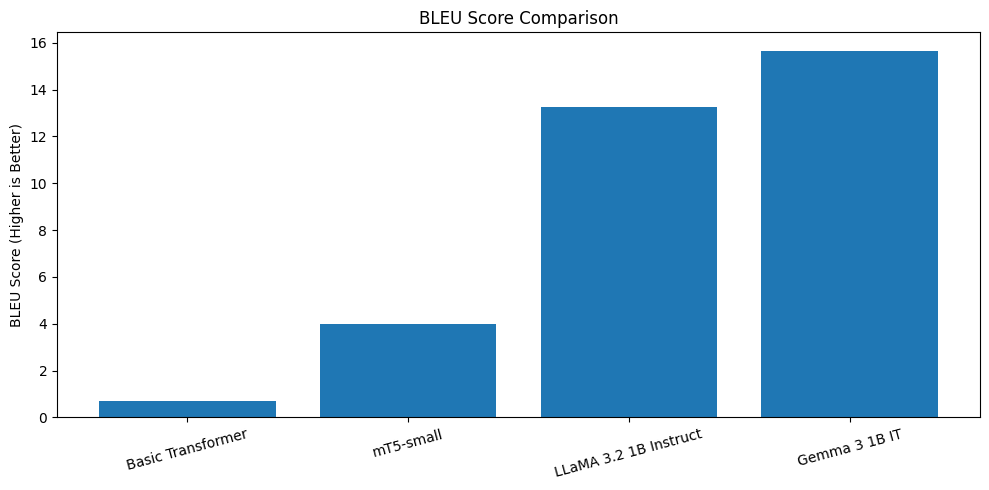

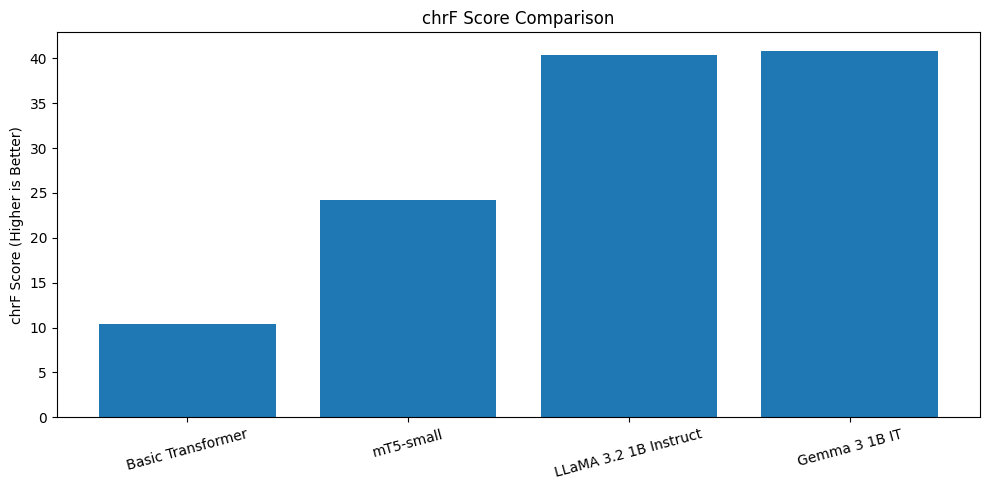

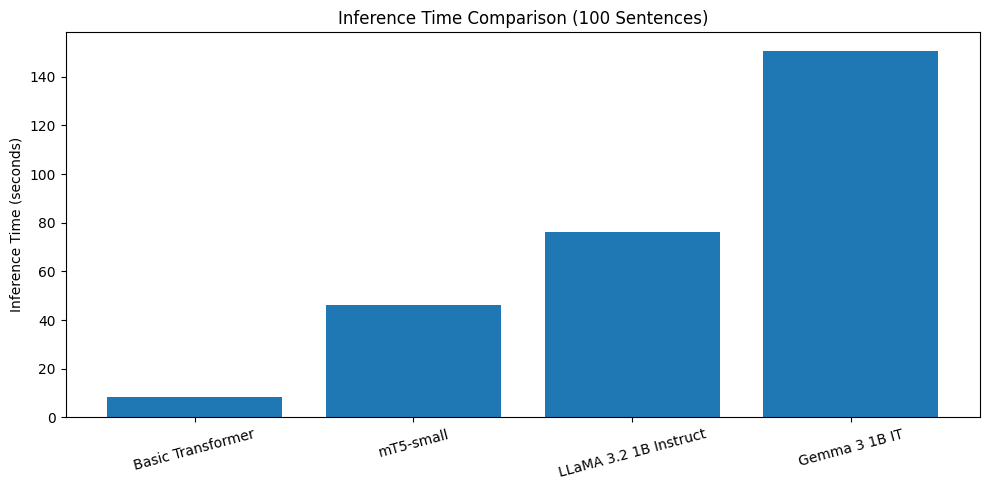

All comparison graphs saved successfully!


In [15]:
import matplotlib.pyplot as plt

# BLEU comparison
plt.figure(figsize=(10, 5))
plt.bar(comparison_df["Model"], comparison_df["BLEU"])
plt.title("BLEU Score Comparison")
plt.ylabel("BLEU Score (Higher is Better)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig("bleu_comparison.png", dpi=300)
plt.show()

# chrF comparison
plt.figure(figsize=(10, 5))
plt.bar(comparison_df["Model"], comparison_df["chrF"])
plt.title("chrF Score Comparison")
plt.ylabel("chrF Score (Higher is Better)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig("chrf_comparison.png", dpi=300)
plt.show()

# Inference time comparison
plt.figure(figsize=(10, 5))
plt.bar(
    comparison_df["Model"],
    comparison_df["Inference_Time_s"]
)
plt.title("Inference Time Comparison (100 Sentences)")
plt.ylabel("Inference Time (seconds)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig("inference_time_comparison.png", dpi=300)
plt.show()

print("All comparison graphs saved successfully!")

# 10. Responsible and Ethical AI Analysis

## Bias

Machine translation systems can reproduce biases present in their training datasets. These may include gender stereotypes, occupational assumptions, and culturally biased expressions.

**Mitigation:** Evaluate translations using diverse demographic and cultural examples, and use human review for sensitive translations.

## Hallucination and Meaning Distortion

Translation models may generate information that was not present in the original text, omit important details, or change the intended meaning.

In this experiment, some generated translations were grammatically plausible but differed from the reference translations in wording or meaning.

**Mitigation:** Use source-faithfulness checks, terminology constraints, and human verification for important translations.

## Cultural Misrepresentation

Literary texts contain idioms, historical expressions, and culturally specific references that may not translate directly between languages.

The OPUS Books dataset includes literary translations, making preservation of meaning and style especially important.

**Mitigation:** Use culturally diverse parallel datasets and native-speaker evaluation.

## Sensitive Content

Incorrect translation of medical, legal, financial, or other sensitive information may have serious consequences.

**Mitigation:** Use domain-specific evaluation, protect sensitive user information, and involve qualified human translators in high-stakes applications.

## Responsible AI Conclusion

Automatic metrics such as BLEU and chrF provide useful quantitative comparisons but do not fully measure factual faithfulness, fairness, cultural appropriateness, or safety.

Human evaluation remains necessary, particularly when translations may affect important decisions.

# 11. Conclusion

This project compared four neural machine translation models for English-to-French translation using the OPUS Books parallel-text dataset.

The Basic Transformer was trained from scratch using PyTorch. mT5-small was fine-tuned on a subset of the training data, while LLaMA 3.2 1B Instruct and Gemma 3 1B IT were evaluated using instruction prompting with 4-bit quantization.

The models were evaluated on the same 100 held-out sentence pairs using BLEU, chrF, inference time, and parameter counts.

**Gemma 3 1B IT achieved the highest translation quality**, with BLEU 15.6651 and chrF 40.8492.

LLaMA 3.2 1B Instruct achieved BLEU 13.2567 and chrF 40.3171, while mT5-small achieved BLEU 3.9855 and chrF 24.2093.

The Basic Transformer achieved the lowest inference time but produced the weakest translations, partly because it was trained from scratch using a relatively small dataset and a limited word-level vocabulary.

The results demonstrate the advantages of pretrained language models for machine translation under the tested conditions.

However, differences in pretraining, model size, tokenization, quantization, and adaptation methods mean that performance differences cannot be attributed solely to encoder–decoder versus decoder-only architecture.

Overall, Gemma was the best-performing model for translation quality in this experiment, while the Basic Transformer was the fastest during inference.

In [16]:
import os

required_files = [
    "basic_transformer_metrics.csv",
    "mt5_metrics.csv",
    "llama_metrics.csv",
    "gemma_metrics.csv",
    "basic_transformer_translations.csv",
    "mt5_translations.csv",
    "llama_translations.csv",
    "gemma_translations.csv",
    "final_model_comparison.csv",
    "translation_evaluation_subset.csv",
    "bleu_comparison.png",
    "chrf_comparison.png",
    "inference_time_comparison.png"
]

missing = [
    filename
    for filename in required_files
    if not os.path.exists(filename)
]

if not missing:
    print("All required result files are available!")
else:
    print("Missing files:")
    for filename in missing:
        print("-", filename)

All required result files are available!


In [17]:
import os
import shutil
import zipfile

output_dir = "/kaggle/working"
results_dir = f"{output_dir}/final_results"

os.makedirs(results_dir, exist_ok=True)

result_files = [
    "basic_transformer_metrics.csv",
    "mt5_metrics.csv",
    "llama_metrics.csv",
    "gemma_metrics.csv",
    "basic_transformer_translations.csv",
    "mt5_translations.csv",
    "llama_translations.csv",
    "gemma_translations.csv",
    "final_model_comparison.csv",
    "translation_evaluation_subset.csv",
    "basic_transformer_training_history.csv",
    "basic_transformer_learning_curve.png",
    "bleu_comparison.png",
    "chrf_comparison.png",
    "inference_time_comparison.png"
]

missing = []

for filename in result_files:
    source = os.path.join(output_dir, filename)

    if os.path.isfile(source):
        shutil.copy2(source, results_dir)
    else:
        missing.append(filename)

zip_path = f"{output_dir}/FGAI_Assignment3_Results.zip"

shutil.make_archive(
    zip_path.removesuffix(".zip"),
    "zip",
    results_dir
)

print("Results ZIP created:", zip_path)
print("Files included:", len(result_files) - len(missing))
print("Missing files:", missing)

Results ZIP created: /kaggle/working/FGAI_Assignment3_Results.zip
Files included: 15
Missing files: []


In [18]:
import os
import shutil

backup_dir = "/kaggle/working/model_backup"
os.makedirs(backup_dir, exist_ok=True)

# Basic Transformer checkpoint
basic_path = "saved_models/basic_transformer_best.pt"

if os.path.exists(basic_path):
    shutil.copy2(basic_path, backup_dir)
else:
    print("Basic Transformer checkpoint not found")

# Complete mT5 checkpoint directory
mt5_path = "saved_models/mt5_finetuned"

if os.path.isdir(mt5_path):
    shutil.copytree(
        mt5_path,
        os.path.join(backup_dir, "mt5_finetuned"),
        dirs_exist_ok=True
    )
else:
    print("mT5 checkpoint directory not found")

shutil.make_archive(
    "/kaggle/working/FGAI_Assignment3_Models",
    "zip",
    backup_dir
)

print("Model backup created!")

Model backup created!


In [19]:
from IPython.display import FileLink, display
import os

files_to_download = [
    "/kaggle/working/FGAI_Assignment3_Results.zip",
    "/kaggle/working/FGAI_Assignment3_Models.zip"
]

for filepath in files_to_download:
    if os.path.exists(filepath):
        print("Ready:", os.path.basename(filepath))
        display(FileLink(filepath))
    else:
        print("Missing:", filepath)

Ready: FGAI_Assignment3_Results.zip


/kaggle/working/FGAI_Assignment3_Results.zip

Ready: FGAI_Assignment3_Models.zip


/kaggle/working/FGAI_Assignment3_Models.zip